In [206]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
import cmdstanpy
from cmdstanpy import CmdStanModel

cmdstanpy.set_cmdstan_path(os.path.expanduser("~/cmdstan"))

from scipy.special import expit as inv_logit, logit
import networkx as nx

np.random.seed(6300)

In [207]:
policy_metadata = pd.read_csv('data/policy-metadata.csv')
policy_metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 645125 entries, 0 to 645124
Data columns (total 27 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Unnamed: 0      645125 non-null  int64  
 1   hash            645125 non-null  object 
 2   year            645125 non-null  int64  
 3   month           645125 non-null  int64  
 4   timestamp       645125 non-null  int64  
 5   uri             645125 non-null  object 
 6   rank            626688 non-null  float64
 7   flesch          645125 non-null  float64
 8   cl              645125 non-null  float64
 9   smog            645125 non-null  float64
 10  wordcount       645125 non-null  float64
 11  sentencecount   645125 non-null  float64
 12  syllablecount   645125 non-null  float64
 13  count_ccpa      645125 non-null  int64  
 14  count_dnt       645125 non-null  int64  
 15  count_gdpr      645125 non-null  int64  
 16  count_p3p       645125 non-null  int64  
 17  count_priv

# Data
- 2043 website privacy policies  (we use the most recent)
- each observation of interest contains a policyId, wordcount, numobfs (number of obfuscating words), flesch (readability score), rank (tranco site ranking)
- we keep the latest snapshot per site

In [208]:
cols = ['policyid', 'uri', 'year', 'timestamp', 'rank', 'wordcount', 'numobfs', 'flesch']
DATA_PATH = './data/policy-metadata.csv' # Mohsen, where is your data sir?
raw = pd.read_csv(DATA_PATH, usecols=cols)

# Most recent snapshot per site (deterministic tie-break)
latest = (raw.sort_values(['uri', 'timestamp', 'policyid'])
             .groupby('uri').tail(1)
             .set_index('uri'))

# Rank is constant within a site, so take the first non-missing value
site_rank = raw.groupby('uri')['rank'].first()
sites = latest[['year', 'wordcount', 'numobfs', 'flesch']].join(site_rank)


# drop extreme flesch values (outliers)
sites = sites[sites['rank'] > 0]
sites = sites[sites['flesch'] >= 0]
print("analysis sites:", len(sites))
print(sites.describe().round(1))

analysis sites: 2043
         year  wordcount  numobfs  flesch      rank
count  2043.0     2043.0   2043.0  2043.0    2043.0
mean   2019.5     3744.5    310.3    32.8   21462.5
std       3.6     5162.6    311.6     9.5   83491.0
min    2000.0      108.0      2.0     0.7       1.0
25%    2021.0     1099.0     99.0    27.3     654.5
50%    2021.0     2720.0    235.0    32.9    1968.0
75%    2021.0     5022.0    446.0    39.3    7135.5
max    2021.0   132546.0   3935.0    72.3  960506.0


In [209]:
sites['R'] = np.log(sites['rank'])
sites['O'] = np.log(sites['numobfs'])
sites['F'] = sites['flesch']

print(sites[['O', 'F', 'R']].describe().round(2))
print(sites[['O', 'F', 'R']].corr().round(2))

             O        F        R
count  2043.00  2043.00  2043.00
mean      5.24    32.76     7.72
std       1.13     9.49     1.93
min       0.69     0.68     0.00
25%       4.60    27.28     6.48
50%       5.46    32.86     7.58
75%       6.10    39.35     8.87
max       8.28    72.28    13.78
      O     F     R
O  1.00 -0.22 -0.17
F -0.22  1.00  0.10
R -0.17  0.10  1.00


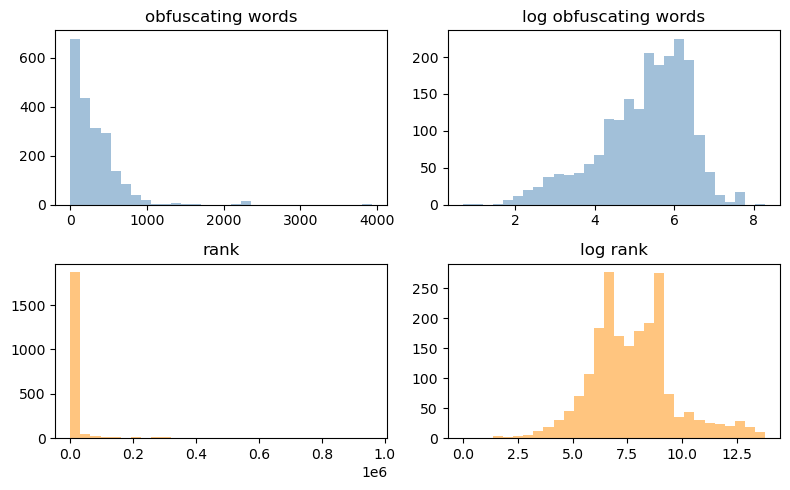

In [210]:
fig, axes = plt.subplots(2, 2, figsize=(8, 5))
axes[0, 0].hist(sites['numobfs'], bins=30, color="steelblue", alpha=0.5)
axes[0, 1].hist(sites['O'],       bins=30, color="steelblue", alpha=0.5)
axes[1, 0].hist(sites['rank'],    bins=30, color="darkorange", alpha=0.5)
axes[1, 1].hist(sites['R'],       bins=30, color="darkorange", alpha=0.5)
for ax, t in zip(axes.flat, ["obfuscating words", "log obfuscating words", "rank", "log rank"]):
    ax.set_title(t)

plt.tight_layout()
plt.savefig("figures/tails.png", dpi=150, bbox_inches="tight")

In [211]:
from pathlib import Path
stan_code = r"""
data {
  int<lower=1> N;
  int<lower=2> K;
  matrix[N, K] X;
  vector[N] y;
  real alpha_mean;
  real<lower=0> alpha_sd;
  real<lower=0> beta_sd;
}
parameters {
  vector[K] beta;
  real<lower=0> sigma;
}
model {
  beta[1] ~ normal(alpha_mean, alpha_sd);
  beta[2:K] ~ normal(0, beta_sd);
  sigma ~ exponential(1);
  y ~ normal_id_glm(X, 0, beta, sigma);
}
"""
stan_path = Path("linear_regression.stan")
stan_path.write_text(stan_code)
regression_model = CmdStanModel(stan_file=str(stan_path))

regression_model = CmdStanModel(stan_file=str(stan_path))

def dag(edges, pos=None):
    graph = nx.DiGraph(edges)
    if pos is None:
        pos = nx.spring_layout(graph, seed=6)
    plt.figure(figsize=(4, 3))
    nx.draw_networkx(graph, pos, node_color="white", edgecolors="black",
                     node_size=860, arrowsize=22, font_size=12)
    plt.axis("off")
    return graph

def norm(n, mu=0, sigma=1):
    """Normal draws."""
    return np.random.normal(mu, sigma, size=n)

def corr(x, y):
    """Pearson correlation."""
    return np.corrcoef(x, y)[0, 1]

def regress(y, X, alpha_sd=1, beta_sd=1, alpha_mean=0, **sample_kwargs):
    """Regress y on x with Stan. Takes care of shaping the design matrix."""
    y, X = np.asarray(y, dtype=float), np.asarray(X, dtype=float)
    if X.ndim == 1:
        X = X[:, None]
    design = np.column_stack([np.ones(len(y)), X])
    data = dict(N=len(y), K=design.shape[1], X=design, y=y,
                alpha_mean=alpha_mean, alpha_sd=alpha_sd, beta_sd=beta_sd)
    options = dict(chains=2, parallel_chains=2, iter_warmup=500,
                   iter_sampling=1000, seed=6300, inits=0, step_size=0.01,
                   show_progress=False)
    options.update(sample_kwargs)
    return regression_model.sample(data=data, **options)

def plot_regression(fit_1, fit_2, title="", target=None):
    plt.figure(figsize=(6, 2.4))
    for row, (label, fit) in enumerate([("Model 1", fit_1), ("Model 2", fit_2)]):
        b = fit.stan_variable("beta")[:, 1]
        print(f"{label}: β_O = {b.mean():.2f} [{np.quantile(b, 0.05):.2f}, {np.quantile(b, 0.95):.2f}]")
        lo, hi = np.quantile(b, [0.05, 0.95])
        plt.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
        plt.plot(b.mean(), row, "o", color=f"C{row}")
    plt.yticks([0, 1], ["Model 1", "Model 2"])
    plt.gca().invert_yaxis()
    plt.axvline(0, color="0.5", linestyle="--")
    plt.xlabel(r"$\beta_O$")
    if target is not None:
        plt.axvline(target, color="C0", linestyle=":")

    plt.savefig(f"figures/{title}.png", bbox_inches="tight", dpi=300)

def plot_slopes(models, xlabel, title=None, target=None):
    """models: list of (label, fit, k), where k is the column of beta to plot
    (0 = intercept, 1 = first slope, 2 = second slope)."""
    fig, ax = plt.subplots(figsize=(6, 0.8 + 0.8 * len(models)))
    for row, (label, fit, k) in enumerate(models):
        b = fit.stan_variable("beta")[:, k]
        lo, hi = np.quantile(b, [0.05, 0.95])
        print(f"{label}: {xlabel} = {b.mean():.2f} [{lo:.2f}, {hi:.2f}]")
        ax.plot([lo, hi], [row, row], color=f"C{row}", lw=2)
        ax.plot(b.mean(), row, "o", color=f"C{row}")
    ax.set_yticks(range(len(models)), [m[0] for m in models])
    ax.invert_yaxis()
    ax.axvline(0, color="0.5", linestyle="--")
    if target is not None:
        ax.axvline(target, color="k", linestyle=":")
    ax.set_xlabel(xlabel)
    if title:
        fig.savefig(f"figures/{title}.png", bbox_inches="tight", dpi=300)


ALPHA_MEAN, ALPHA_SD, BETA_SD = 8, 1, 0.5
priors = dict(alpha_mean=ALPHA_MEAN, alpha_sd=ALPHA_SD, beta_sd=BETA_SD)

def center(x):
    """Subtract the mean. Shifts the variable but does not rescale it, so slopes keep their units."""
    x = np.asarray(x, dtype=float)
    return x - x.mean()

o_centered = center(sites['O'])
f_centered = center(sites['F'] / 10)
r_log = sites['R']


10:44:58 - cmdstanpy - INFO - compiling stan file /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression.stan to exe file /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression
10:45:09 - cmdstanpy - INFO - compiled model executable: /Users/marobinette/bayesian_statistics/portfolio/3/linear_regression


# 2 Causal graph and question

$O$ = log number of obfuscating words in the policy, $F$ = Flesch reading ease score (higher is easier to read), $R$ = log Tranco rank (lower means a more popular site).

**Causal question.** If there were a policy that required a site's privacy policy readability (Flesch score) to be a chosen value $f$, how would the site's log Tranco rank change? We compare $E[R \mid do(F = f)]$ across values of $f$.

**Graph.** $O \rightarrow F \rightarrow R$. Intervening on $F$ removes the arrow $O \rightarrow F$, so it does not matter how readability is achieved (fewer obfuscating words or fewer passive sentences). The graph is a pipe, so it implies $R \perp O \mid F$.

**Assumptions (missing arrows).** No direct arrow from $O$ to $R$. No shared cause of $F$ and $R$ other than through $O$.

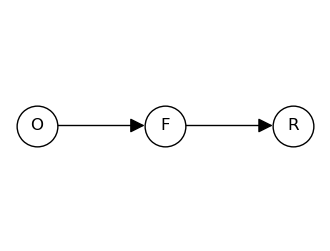

In [212]:
dag([("O", "F"), ("F", "R")], {"O": (-1, 0), "F": (0, 0), "R": (1, 0)});
plt.savefig("figures/dag.png", bbox_inches="tight", dpi=300)

# Fake-data model

For each site $i = 1, \dots, n$ with $n = 2043$:

$$O_i \sim N(5,\ 1)$$
$$F_i \mid O_i \sim N(30 - 4\,(O_i - 5),\ 8)$$
$$R_i \mid F_i \sim N(7 - 0.08\,(F_i - 32),\ 2)$$

The means and SDs of O, F and R match the real data (log obfuscating words, Flesch score, log rank). The true total effect of O on R is $(-4)(-0.08) \approx +0.32$. The true effect of the intervention $do(F = f)$ on R is $-0.08$ per Flesch point. The graph implies **R ⟂ O | F**.

# 3 Fake-data model

In [213]:
np.random.seed(6300)
n = 2043
O_sim = norm(n, 5, 1)
F_sim = norm(n, 30 - 4 * (O_sim - 5), 8)
R_sim = norm(n, 7 - 0.08 * (F_sim - 32), 2)

print("corr(O, F):", round(corr(O_sim, F_sim), 3))
print("corr(F, R):", round(corr(F_sim, R_sim), 3))
print("corr(O, R):", round(corr(O_sim, R_sim), 3))
print("means:", round(O_sim.mean(), 2), round(F_sim.mean(), 2), round(R_sim.mean(), 2))
print("SDs:", round(O_sim.std(), 2), round(F_sim.std(), 2), round(R_sim.std(), 2))

corr(O, F): -0.441
corr(F, R): -0.351
corr(O, R): 0.15
means: 5.01 29.79 7.16
SDs: 1.01 9.07 2.15


In [214]:
O_c_sim = center(O_sim)
F_c_sim = center(F_sim / 10)

fake_fit1 = regress(R_sim, O_c_sim, **priors)                           # R ~ O
fake_fit2 = regress(R_sim, np.column_stack([O_c_sim, F_c_sim]), **priors)   # R ~ O + F
fake_fit3 = regress(R_sim, F_c_sim, **priors)                           # R ~ F

for name, fit in [("Model 1", fake_fit1), ("Model 2", fake_fit2), ("Model 3", fake_fit3)]:
    print(name)
    print(fit.summary().round(3))

10:45:10 - cmdstanpy - INFO - CmdStan start processing
10:45:10 - cmdstanpy - INFO - Chain [1] start processing
10:45:10 - cmdstanpy - INFO - Chain [2] start processing
10:45:10 - cmdstanpy - INFO - Chain [1] done processing
10:45:10 - cmdstanpy - INFO - Chain [2] done processing
10:45:10 - cmdstanpy - INFO - CmdStan start processing
10:45:10 - cmdstanpy - INFO - Chain [1] start processing
10:45:10 - cmdstanpy - INFO - Chain [2] start processing
10:45:10 - cmdstanpy - INFO - Chain [1] done processing
10:45:10 - cmdstanpy - INFO - Chain [2] done processing
10:45:10 - cmdstanpy - INFO - CmdStan start processing
10:45:10 - cmdstanpy - INFO - Chain [1] start processing
10:45:10 - cmdstanpy - INFO - Chain [2] start processing
10:45:11 - cmdstanpy - INFO - Chain [1] done processing
10:45:11 - cmdstanpy - INFO - Chain [2] done processing


Model 1
             Mean   MCSE  StdDev    MAD        5%       50%       95%  \
lp__    -2561.170  0.039   1.201  0.979 -2563.530 -2560.870 -2559.860   
beta[1]     7.160  0.001   0.046  0.046     7.086     7.160     7.235   
beta[2]     0.316  0.001   0.046  0.047     0.243     0.316     0.390   
sigma       2.122  0.001   0.033  0.035     2.069     2.121     2.177   

         ESS_bulk  ESS_tail  ESS_bulk/s  R_hat  
lp__      1070.49   1081.41      8363.2  1.001  
beta[1]   1828.63   1431.31     14286.1  1.000  
beta[2]   1660.65   1334.00     12973.8  1.000  
sigma     2148.74   1529.01     16787.0  1.001  
Model 2
             Mean   MCSE  StdDev    MAD        5%       50%       95%  \
lp__    -2451.380  0.047   1.436  1.233 -2454.120 -2451.050 -2449.690   
beta[1]     7.161  0.001   0.044  0.042     7.087     7.161     7.235   
beta[2]    -0.009  0.001   0.049  0.049    -0.089    -0.009     0.072   
beta[3]    -0.827  0.001   0.054  0.052    -0.912    -0.828    -0.734   
sigma   

Model 1
Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Rank-normalized split effective sample size satisfactory for all parameters.

Rank-normalized split R-hat values satisfactory for all parameters.

Processing complete, no problems detected.

Model 2
Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Rank-normalized split effective sample size satisfactory for all parameters.

Rank-normalized split R-hat values satisfactory for all parameters.

Processing complete, no problems detected.

Model 3
Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler 

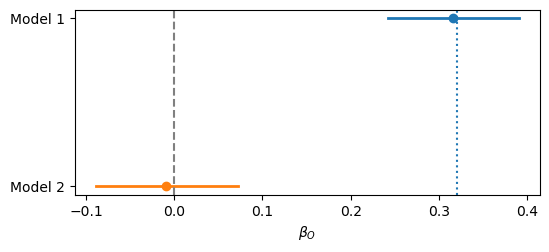

In [215]:
# I am leaving model3 so we can verify that leaving O out doesn't chnagge F's slope
for name, fit in [("Model 1", fake_fit1), ("Model 2", fake_fit2), ("Model 3", fake_fit3)]:
    print(name)
    print(fit.diagnose())

plot_regression(fake_fit1, fake_fit2, title="simulated", target=0.32)

$O$ and $R$ are associated (Model 1). Once we condition on $F$ (Model 2), that association is gone.

In [216]:
prior_predictive_stan = r"""
data {
  int<lower=1> N;
  int<lower=2> K;
  matrix[N, K] X;
  real alpha_mean;
  real<lower=0> alpha_sd;
  real<lower=0> beta_sd;
}
generated quantities {
  vector[K] beta;
  real<lower=0> sigma = exponential_rng(1);
  beta[1] = normal_rng(alpha_mean, alpha_sd);
  for (k in 2:K) {
    beta[k] = normal_rng(0, beta_sd);
  }
  array[N] real y_rep = normal_rng(X * beta, sigma);
}
"""

10:45:12 - cmdstanpy - INFO - compiling stan file /Users/marobinette/bayesian_statistics/portfolio/3/prior_predictive.stan to exe file /Users/marobinette/bayesian_statistics/portfolio/3/prior_predictive
10:45:17 - cmdstanpy - INFO - compiled model executable: /Users/marobinette/bayesian_statistics/portfolio/3/prior_predictive
10:45:18 - cmdstanpy - INFO - CmdStan start processing
10:45:18 - cmdstanpy - INFO - Chain [1] start processing
10:45:19 - cmdstanpy - INFO - Chain [1] done processing


quantiles (1, 5, 50, 95, 99%): [ 2.5  5.1  8.1 11.1 13.5]
share outside [0, 13.8]: 0.011


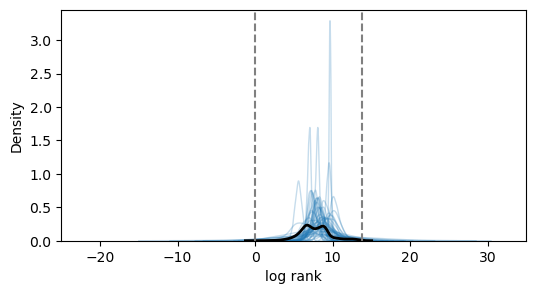

In [217]:
pp_path = Path("prior_predictive.stan")
pp_path.write_text(prior_predictive_stan)
pp_model = CmdStanModel(stan_file=str(pp_path))

X_real_c = np.column_stack([np.ones(len(sites)), o_centered, f_centered])
pp_data_c = dict(N=len(sites), K=3, X=X_real_c, alpha_mean=8, alpha_sd=1, beta_sd=0.5)

pp_fit_c = pp_model.sample(data=pp_data_c, fixed_param=True, chains=1,
                           iter_sampling=1000, seed=6300, show_progress=False)
y_rep_c = pp_fit_c.stan_variable("y_rep")

print("quantiles (1, 5, 50, 95, 99%):", np.quantile(y_rep_c, [0.01, 0.05, 0.5, 0.95, 0.99]).round(1))
print("share outside [0, 13.8]:", np.mean((y_rep_c < 0) | (y_rep_c > 13.8)).round(3))

fig, ax = plt.subplots(figsize=(6, 3))
for i in range(50):
    sns.kdeplot(y_rep_c[i], ax=ax, color="C0", alpha=0.25, lw=1)
sns.kdeplot(sites['R'], ax=ax, color="k", lw=2)
ax.axvline(0, color="0.5", linestyle="--")
ax.axvline(13.8, color="0.5", linestyle="--")
ax.set_xlim(-25, 35)
ax.set_xlabel("log rank")
plt.savefig("figures/prior_predictive_centered.png", bbox_inches="tight", dpi=300)

In [218]:
real_fit1 = regress(r_log, o_centered, **priors)                              # R ~ O
real_fit2 = regress(r_log, np.column_stack([o_centered, f_centered]), **priors)      # R ~ O + F
real_fit3 = regress(r_log, f_centered, **priors)                              # R ~ F

for name, fit in [("Model 1", real_fit1), ("Model 2", real_fit2), ("Model 3", real_fit3)]:
    print(name)
    print(fit.summary().round(3))

10:45:21 - cmdstanpy - INFO - CmdStan start processing
10:45:21 - cmdstanpy - INFO - Chain [1] start processing
10:45:21 - cmdstanpy - INFO - Chain [2] start processing
10:45:21 - cmdstanpy - INFO - Chain [1] done processing
10:45:21 - cmdstanpy - INFO - Chain [2] done processing
10:45:21 - cmdstanpy - INFO - CmdStan start processing
10:45:21 - cmdstanpy - INFO - Chain [1] start processing
10:45:21 - cmdstanpy - INFO - Chain [2] start processing
10:45:21 - cmdstanpy - INFO - Chain [1] done processing
10:45:21 - cmdstanpy - INFO - Chain [2] done processing
10:45:21 - cmdstanpy - INFO - CmdStan start processing
10:45:21 - cmdstanpy - INFO - Chain [1] start processing
10:45:21 - cmdstanpy - INFO - Chain [2] start processing
10:45:22 - cmdstanpy - INFO - Chain [1] done processing
10:45:22 - cmdstanpy - INFO - Chain [2] done processing


Model 1
             Mean   MCSE  StdDev    MAD        5%       50%       95%  \
lp__    -2337.430  0.037   1.225  1.016 -2339.760 -2337.140 -2336.130   
beta[1]     7.723  0.001   0.041  0.041     7.657     7.723     7.790   
beta[2]    -0.293  0.001   0.037  0.037    -0.355    -0.293    -0.232   
sigma       1.902  0.001   0.030  0.031     1.854     1.902     1.952   

         ESS_bulk  ESS_tail  ESS_bulk/s  R_hat  
lp__      1188.57   1254.61     9004.33  1.000  
beta[1]   1859.84   1503.26    14089.70  1.001  
beta[2]   1993.15   1473.57    15099.60  1.000  
sigma     1851.76   1288.09    14028.50  0.999  
Model 2
             Mean   MCSE  StdDev    MAD        5%       50%       95%  \
lp__    -2334.050  0.044   1.411  1.179 -2336.760 -2333.700 -2332.450   
beta[1]     7.725  0.001   0.042  0.043     7.654     7.726     7.793   
beta[2]    -0.269  0.001   0.038  0.037    -0.333    -0.268    -0.209   
beta[3]     0.126  0.001   0.044  0.042     0.056     0.125     0.198   
sigma   

In [219]:
print(f"model 1 divergence check: {real_fit1.diagnose()}")
print(f"model 2 divergence check: {real_fit2.diagnose()}")
print(f"model 3 divergence check: {real_fit3.diagnose()}")

model 1 divergence check: Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Rank-normalized split effective sample size satisfactory for all parameters.

Rank-normalized split R-hat values satisfactory for all parameters.

Processing complete, no problems detected.

model 2 divergence check: Checking sampler transitions treedepth.
Treedepth satisfactory for all transitions.

Checking sampler transitions for divergences.
No divergent transitions found.

Checking E-BFMI - sampler transitions HMC potential energy.
E-BFMI satisfactory.

Rank-normalized split effective sample size satisfactory for all parameters.

Rank-normalized split R-hat values satisfactory for all parameters.

Processing complete, no problems detected.

model 3 divergence check: Checking sampler transitions treedepth.
Treedept

F_raw.std(): 9.49, F_raw.min(): 0.68, F_raw.max(): 72.28


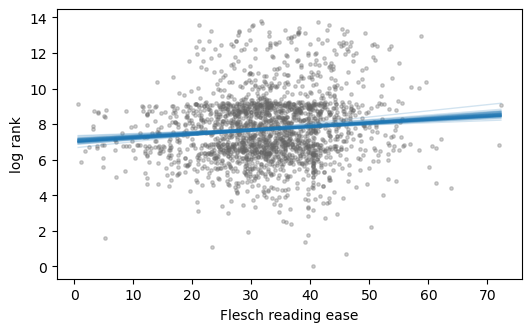

In [222]:
F_raw = sites['F'].to_numpy()
R_raw = sites['R'].to_numpy()

draws = real_fit3.stan_variable("beta")          # columns: intercept, slope on centered F/10
x = np.linspace(F_raw.min(), F_raw.max(), 50)
x_c = x / 10 - (F_raw / 10).mean()               # same centering as the fit

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.scatter(F_raw, R_raw, s=6, alpha=0.3, color="0.4")
for a, b in draws[:50]:
    ax.plot(x, a + b * x_c, color="C0", alpha=0.2, lw=1)
ax.set_xlabel("Flesch reading ease")
ax.set_ylabel("log rank")
plt.savefig("figures/rank_flesch.png", bbox_inches="tight", dpi=300)

# print(draws.mean(axis=0), draws.std(axis=0), draws.max(axis=0), draws.min(axis=0), np.quantile(draws, [0.05, 0.95], axis=0))
print(f"F_raw.std(): {F_raw.std():.2f}, F_raw.min(): {F_raw.min():.2f}, F_raw.max(): {F_raw.max():.2f}")

Model 1: β_O = -0.29 [-0.35, -0.23]
Model 2: β_O = -0.27 [-0.33, -0.21]


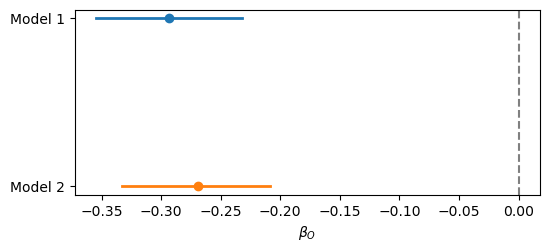

In [221]:
plot_regression(real_fit1, real_fit2, title="real_data")

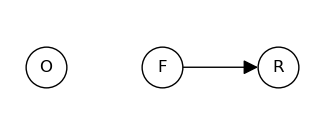

In [223]:
plt.figure(figsize=(4, 1.5))
g = nx.DiGraph([("F", "R")])
g.add_node("O")
nx.draw_networkx(g, {"O": (-1, 0), "F": (0, 0), "R": (1, 0)},
                 node_color="white", edgecolors="black",
                 node_size=860, arrowsize=22, font_size=12)
plt.margins(x=0.15, y=0.5)
plt.axis("off")
plt.savefig("figures/dag_do.png", bbox_inches="tight", dpi=300)

do(F=20) [7.359 7.474 7.589]
do(F=40) [7.778 7.866 7.959]
contrast [0.251 0.392 0.54 ]


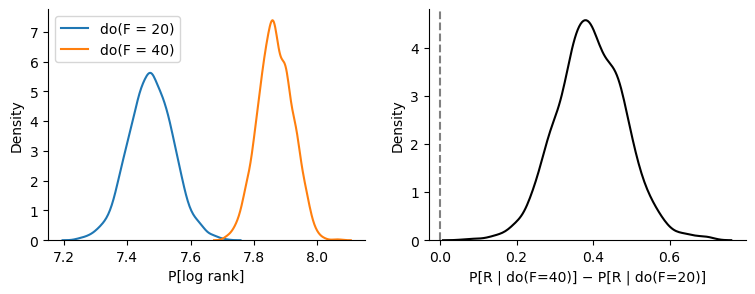

In [224]:
beta = real_fit3.stan_variable("beta")   # [:, 0] intercept, [:, 1] slope on F
f_mean = (sites['F'] / 10).mean()

def do_F(f):
    return beta[:, 0] + beta[:, 1] * (f / 10 - f_mean)

R_20, R_40 = do_F(20), do_F(40)
contrast = R_40 - R_20

for name, x in [("do(F=20)", R_20), ("do(F=40)", R_40), ("contrast", contrast)]:
    print(name, np.quantile(x, [0.05, 0.5, 0.95]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
sns.kdeplot(R_20, ax=ax[0], label="do(F = 20)")
sns.kdeplot(R_40, ax=ax[0], label="do(F = 40)")
ax[0].set_xlabel("P[log rank]"); ax[0].legend()
sns.kdeplot(contrast, ax=ax[1], color="k")
ax[1].axvline(0, color="0.5", linestyle="--")
ax[1].set_xlabel("P[R | do(F=40)] − P[R | do(F=20)]")
sns.despine()
plt.savefig("figures/do_F.png", bbox_inches="tight", dpi=300)